In [1]:
import numpy as np

def ecuacion_pendulo(estado, L, g=9.81, gamma=0.0):
    """
    Calcula las derivadas [dtheta/dt, domega/dt] del péndulo simple.
    estado: arreglo [theta, omega] en radianes y rad/s.
    L: longitud de la cuerda en metros.
    gamma: coeficiente de amortiguamiento (0.0 = péndulo ideal conservativo).
    """
    theta, omega = estado
    dtheta = omega
    domega = -(g / L) * np.sin(theta) - gamma * omega
    return np.array([dtheta, domega])

def paso_rk4(estado, L, dt, g=9.81, gamma=0.0):
    """Avanza un paso temporal dt usando Runge-Kutta de orden 4."""
    k1 = ecuacion_pendulo(estado, L, g, gamma)
    k2 = ecuacion_pendulo(estado + 0.5 * dt * k1, L, g, gamma)
    k3 = ecuacion_pendulo(estado + 0.5 * dt * k2, L, g, gamma)
    k4 = ecuacion_pendulo(estado + dt * k3, L, g, gamma)
    return estado + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

def generar_trayectoria(L, theta0_deg, omega0=0.0, dt=0.005, pasos_guardados=1000, cada=4):
    """
    Simula una trayectoria completa y devuelve una matriz de forma (pasos_guardados, 3)
    cuyas columnas son: [theta(t), omega(t), L].
    Con dt=0.005 y cada=4, el paso efectivo guardado es dt_datos = 0.02 s (20 segundos totales).
    """
    estado = np.array([np.radians(theta0_deg), omega0], dtype=float)
    trayectoria = np.zeros((pasos_guardados, 3))
    
    fila = 0
    paso = 0
    while fila < pasos_guardados:
        if paso % cada == 0:
            trayectoria[fila] = [estado[0], estado[1], L]
            fila += 1
        estado = paso_rk4(estado, L, dt)
        paso += 1
        
    return trayectoria

if __name__ == "__main__":
    # Parámetros de simulación
    dt_integracion = 0.005
    cada = 4
    dt_datos = dt_integracion * cada  # 0.02 s entre muestras guardadas
    pasos_guardados = 1000            # 20 segundos por trayectoria

    # 1. Conjunto de entrenamiento: 6 longitudes x 2 ángulos iniciales = 12 series
    longitudes_train = [0.5, 0.8, 1.1, 1.4, 1.7, 2.0]
    angulos_train = [40.0, 100.0]

    bloques_train = []
    id_serie = 0
    for L in longitudes_train:
        for theta0 in angulos_train:
            serie = generar_trayectoria(
                L=L,
                theta0_deg=theta0,
                omega0=0.0,
                dt=dt_integracion,
                pasos_guardados=pasos_guardados,
                cada=cada
            )
            # Agregamos una columna con el identificador de la serie (0 a 11)
            columna_id = np.full((pasos_guardados, 1), id_serie)
            bloques_train.append(np.hstack([columna_id, serie]))
            id_serie += 1

    # Apilamos en una matriz 2D de forma (12000, 4) -> [id_serie, theta, omega, L]
    datos_train_2d = np.vstack(bloques_train)

    np.savetxt(
        "pendulo_train.txt",
        datos_train_2d,
        fmt=["%d", "%.8f", "%.8f", "%.4f"],
        header="id_serie theta(rad) omega(rad/s) L(m)"
    )

    # 2. Trayectoria de prueba: longitud intermedia NO vista en entrenamiento (L = 1.25 m)
    L_test = 1.25
    theta0_test = 70.0
    trayectoria_test = generar_trayectoria(
        L=L_test,
        theta0_deg=theta0_test,
        omega0=0.0,
        dt=dt_integracion,
        pasos_guardados=pasos_guardados,
        cada=cada
    )

    np.savetxt(
        "pendulo_test.txt",
        trayectoria_test,
        fmt="%.8f",
        header="theta(rad) omega(rad/s) L(m)"
    )

    print(f"Archivo 'pendulo_train.txt' guardado con forma: {datos_train_2d.shape}")
    print(f"Archivo 'pendulo_test.txt' guardado con forma: {trayectoria_test.shape} (L={L_test} m, theta0={theta0_test}°)")


Archivo 'pendulo_train.txt' guardado con forma: (12000, 4)
Archivo 'pendulo_test.txt' guardado con forma: (1000, 3) (L=1.25 m, theta0=70.0°)


In [2]:
datos_train_2d = np.loadtxt("pendulo_train.txt")
ids_series = np.unique(datos_train_2d[:, 0])

# Reconstruimos la lista de 12 arreglos de forma (1000, 3) -> [theta, omega, L]
trayectorias_train = [
    datos_train_2d[datos_train_2d[:, 0] == i, 1:] for i in ids_series
]

U_test = np.loadtxt("pendulo_test.txt")  # Arreglo de forma (1000, 3) para L = 1.25 m
dt_datos = 0.02

Series cargadas: 12 | Pasos por serie: 1000
RMSE en ángulo theta (L=1.25 m): 0.80279 rad (45.996°)
RMSE en velocidad omega (L=1.25 m): 2.32808 rad/s


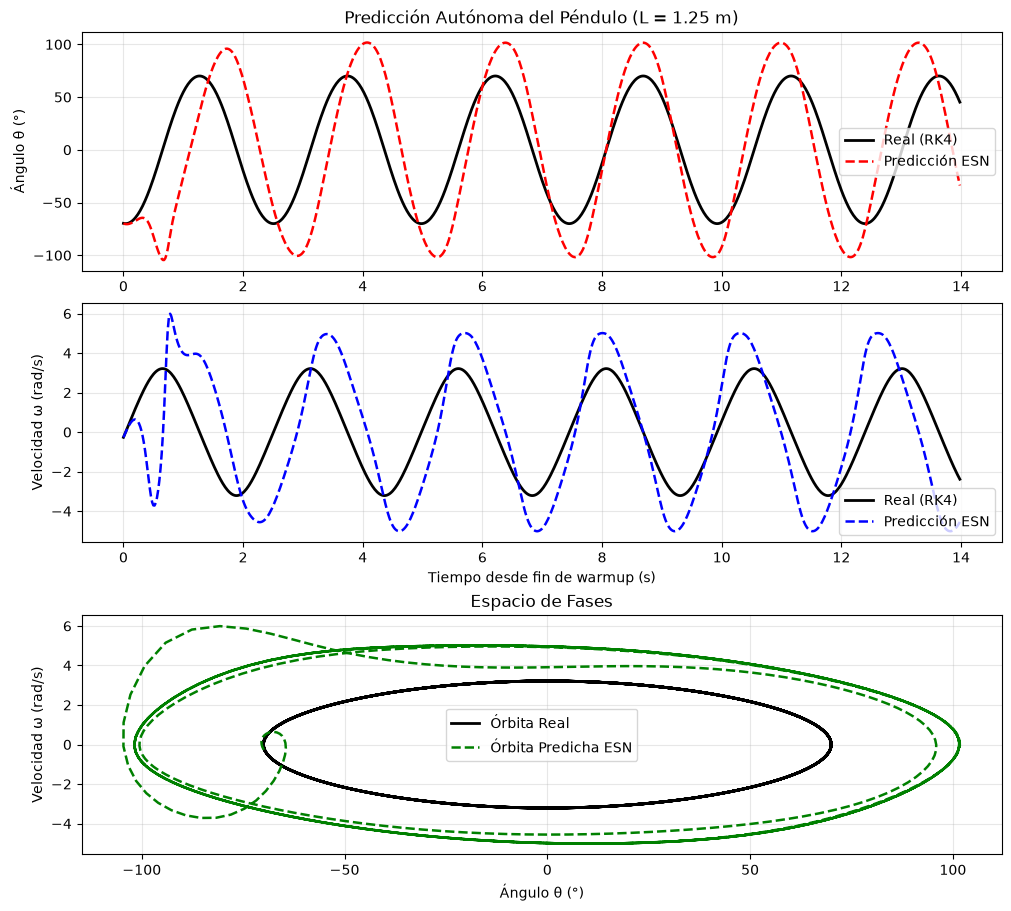

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from reservoirpy.nodes import Reservoir, Ridge


datos_train = np.loadtxt("pendulo_train.txt")
ids_unicos = np.unique(datos_train[:, 0])

# Separamos cada trayectoria en un arreglo 2D independiente (pasos, 3)
trayectorias_train = [
    datos_train[datos_train[:, 0] == idx, 1:4] for idx in ids_unicos
]


datos_test = np.loadtxt("pendulo_test.txt")
U_test = datos_test[:, 1:4] if datos_test.shape[1] == 4 else datos_test

dt_datos = 0.02  # Paso efectivo guardado en la simulación (dt=0.005 * cada=4)


todas_train = np.vstack(trayectorias_train)  # Apilado temporal solo para medir escala
media = todas_train.mean(axis=0)             # media_theta, media_omega, media_L
std = todas_train.std(axis=0)                # [std_theta, std_omega, std_L]
std = np.where(std == 0, 1.0, std)

train_norm = [(U - media) / std for U in trayectorias_train]
U_test_norm = (U_test - media) / std


X_train_list = [U[:-1, :] for U in train_norm]
Y_train_list = [U[1:, :2] for U in train_norm]


reservoir = Reservoir(
    units=500,               # Neuronas internas del reservorio
    lr=0.7,                  # Memoria
    sr=0.5,                  # Radio espectral (< 1 para propiedad de eco)
    input_scaling=0.5,       # Escala de entrada para trabajar en zona útil de tanh
    input_connectivity=0.2,  # Densidad de conexiones de entrada
    rc_connectivity=0.1,     # Densidad de conexiones recurrentes internas
    seed=42
)

readout = Ridge(ridge=1e-5)               # Regularización L2 para calcular W_out)

ESN = reservoir >> readout


ESN.fit(X_train_list, Y_train_list, warmup=500)


step_warmup = 60        # Pasos reales iniciales para sincronizar con L_test
step_prediccion = 700   # Pasos futuros predichos de forma autónoma (14 s)

# Fase A: Sincronización (Teacher Forcing)
pred_warmup = ESN.run(U_test_norm[:step_warmup, :])

# Fase B: Generación autónoma
predicciones_norm = np.zeros((step_prediccion, 2))
estado_actual = pred_warmup[-1].ravel()  # Primera predicción tras el warmup
L_test_norm = U_test_norm[0, 2]          # Longitud normalizada constante
predicciones_norm[0] = estado_actual

for t in range(1, step_prediccion):
    entrada_actual = np.array([[estado_actual[0], estado_actual[1], L_test_norm]]).ravel()
    estado_actual = ESN(entrada_actual).ravel()
    predicciones_norm[t] = estado_actual


Y_pred = predicciones_norm * std[:2] + media[:2]
Y_real = U_test[step_warmup : step_warmup + step_prediccion, :2]

rmse_theta = np.sqrt(np.mean((Y_real[:, 0] - Y_pred[:, 0])**2))
rmse_omega = np.sqrt(np.mean((Y_real[:, 1] - Y_pred[:, 1])**2))
print(f"Series cargadas: {len(trayectorias_train)} | Pasos por serie: {trayectorias_train[0].shape[0]}")
print(f"RMSE en ángulo theta (L={U_test[0,2]} m): {rmse_theta:.5f} rad ({np.degrees(rmse_theta):.3f}°)")
print(f"RMSE en velocidad omega (L={U_test[0,2]} m): {rmse_omega:.5f} rad/s")


tiempo = np.arange(step_prediccion) * dt_datos
fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)

axes[0].plot(tiempo, np.degrees(Y_real[:, 0]), "k-", lw=2, label="Real (RK4)")
axes[0].plot(tiempo, np.degrees(Y_pred[:, 0]), "r--", lw=1.8, label="Predicción ESN")
axes[0].set_ylabel("Ángulo θ (°)")
axes[0].set_title(f"Predicción Autónoma del Péndulo (L = {U_test[0, 2]} m)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(tiempo, Y_real[:, 1], "k-", lw=2, label="Real (RK4)")
axes[1].plot(tiempo, Y_pred[:, 1], "b--", lw=1.8, label="Predicción ESN")
axes[1].set_ylabel("Velocidad ω (rad/s)")
axes[1].set_xlabel("Tiempo desde fin de warmup (s)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(np.degrees(Y_real[:, 0]), Y_real[:, 1], "k-", lw=2, label="Órbita Real")
axes[2].plot(np.degrees(Y_pred[:, 0]), Y_pred[:, 1], "g--", lw=1.8, label="Órbita Predicha ESN")
axes[2].set_xlabel("Ángulo θ (°)")
axes[2].set_ylabel("Velocidad ω (rad/s)")
axes[2].set_title("Espacio de Fases")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.show()

In [8]:
import numpy as np

def ecuacion_pendulo(estado, L=1.0, g=9.81, gamma=0.0):
    """Derivadas [dtheta/dt, domega/dt] del péndulo simple."""
    theta, omega = estado
    dtheta = omega
    domega = -(g / L) * np.sin(theta) - gamma * omega
    return np.array([dtheta, domega])

def paso_rk4(estado, L, dt, g=9.81, gamma=0.0):
    """Avanza un paso temporal dt usando Runge-Kutta de orden 4."""
    k1 = ecuacion_pendulo(estado, L, g, gamma)
    k2 = ecuacion_pendulo(estado + 0.5 * dt * k1, L, g, gamma)
    k3 = ecuacion_pendulo(estado + 0.5 * dt * k2, L, g, gamma)
    k4 = ecuacion_pendulo(estado + dt * k3, L, g, gamma)
    return estado + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

# Parámetros físicos del péndulo único
L_unico = 1.0          # Longitud fija (m)
theta0_deg = 70.0      # Ángulo inicial (grados)
omega0 = 0.0           # Velocidad angular inicial (rad/s)

# Parámetros de integración y muestreo
dt_integracion = 0.005
cada = 4
dt_datos = dt_integracion * cada  # 0.02 s entre filas
pasos_guardados = 1500            # 30 segundos totales (~15 periodos completos)

estado = np.array([np.radians(theta0_deg), omega0], dtype=float)
U = np.zeros((pasos_guardados, 2))

fila = 0
paso = 0
while fila < pasos_guardados:
    if paso % cada == 0:
        U[fila] = estado
        fila += 1
    estado = paso_rk4(estado, L_unico, dt_integracion)
    paso += 1

np.savetxt(
    "pendulo_unico.txt",
    U,
    fmt="%.8f",
    header="theta(rad) omega(rad/s)"
)
print(f"Archivo 'pendulo_unico.txt' guardado con forma {U.shape} (L = {L_unico} m)")

Archivo 'pendulo_unico.txt' guardado con forma (1500, 2) (L = 1.0 m)


RMSE en ángulo theta: 0.03778 rad (2.165°)
RMSE en velocidad omega: 0.09882 rad/s


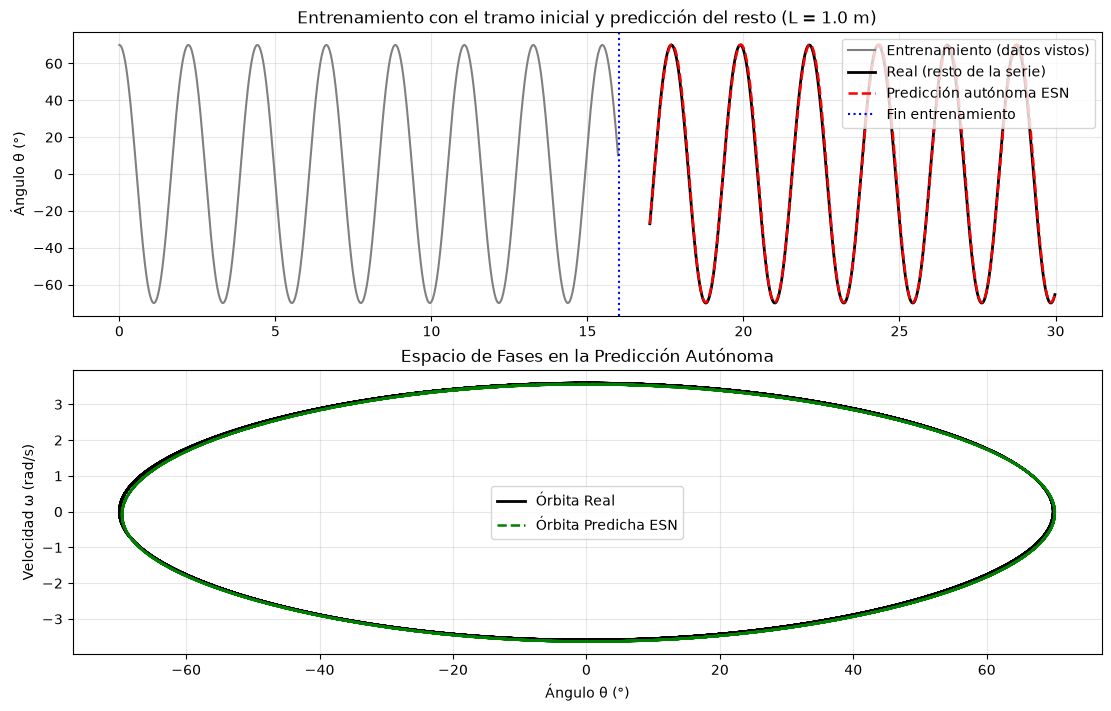

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from reservoirpy.nodes import Reservoir, Ridge


U = np.loadtxt("pendulo_unico.txt")  # Forma: (1500, 2) -> [theta, omega]
dt_datos = 0.02

n_train = 800              # Primeros 16 s (~8 oscilaciones) para entrenar
U_train = U[:n_train]      # Datos iniciales de entrenamiento
U_test = U[n_train:]       # Resto de la serie (700 pasos = 14 s) para evaluar


media = U_train.mean(axis=0)
std = U_train.std(axis=0)

U_train_norm = (U_train - media) / std
U_test_norm = (U_test - media) / std

X_train = U_train_norm[:-1]  # Estado en t
Y_train = U_train_norm[1:]   # Estado en t + 1


reservoir = Reservoir(
    units=300,               # 300 neuronas bastan para una órbita periódica 2D
    lr=0.8,                  # Leaking rate acorde a dt_datos = 0.02 s
    sr=0.1,                  # Radio espectral (< 1 para estabilidad)
    input_scaling=0.5,       # Escala de entrada para aprovechar la no linealidad de tanh
  , np.degrees(U_train[:, 0]), color="gray", lw=1.5, label="Entrenamiento (datos vistos)")
axes[0].plot(t_pred, np.degrees(Y_real[:, 0]), "k-", lw=2, label="Real (resto de la serie)")
axes[0].plot(t_pred, np.degrees(Y_pred[:, 0]), "r--", lw=1.8, label="Predicción autónoma ESN")
axes[0].axvline(t_total[n_train], color="blue", ls=":", lw=1.5, label="Fin entrenamiento")
axes[0].set_ylabel("Ángulo θ (°)")
axes[0].set_title("Entrenamiento con el tramo inicial y predicción del resto (L = 1.0 m)")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)


axes[1].plot(np.degrees(Y_real[:, 0]), Y_real[:, 1], "k-", lw=2, label="Órbita Real")
axes[1].plot(np.degrees(Y_pred[:, 0]), Y_pred[:, 1], "g--", lw=1.8, label="Órbita Predicha ESN")
axes[1].set_xlabel("Ángulo θ (°)")
axes[1].set_ylabel("Velocidad ω (rad/s)")
axes[1].set_title("Espacio de Fases en la Predicción Autónoma")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.show()  input_connectivity=0.2,
    rc_connectivity=0.1,
    seed=42
)
readout = Ridge(ridge=1e-7)

ESN = reservoir >> readout
ESN.fit(X_train, Y_train, warmup=100)  # Descarta los primeros 100 pasos de arranque


step_warmup = 50                                   # Pasos reales para sincronizar el estado
step_prediccion = len(U_test_norm) - step_warmup   # Predice todo el resto (650 pasos)

#Sincronización con el inicio del tramo de prueba
pred_warmup = ESN.run(U_test_norm[:step_warmup])

#Predicción en lazo cerrado (closed-loop)
predicciones_norm = np.zeros((step_prediccion, 2))
u_actual = pred_warmup[-1].ravel()  # Primera predicción tras el warmup
predicciones_norm[0] = u_actual

for t in range(1, step_prediccion):
    u_actual = ESN(u_actual).ravel()  # Retroalimenta su propia salida [theta, omega]
    predicciones_norm[t] = u_actual


Y_pred = predicciones_norm * std + media
Y_real = U_test[step_warmup:]

rmse_theta = np.sqrt(np.mean((Y_real[:, 0] - Y_pred[:, 0])**2))
rmse_omega = np.sqrt(np.mean((Y_real[:, 1] - Y_pred[:, 1])**2))
print(f"RMSE en ángulo theta: {rmse_theta:.5f} rad ({np.degrees(rmse_theta):.3f}°)")
print(f"RMSE en velocidad omega: {rmse_omega:.5f} rad/s")


t_total = np.arange(len(U)) * dt_datos
t_train = t_total[:n, np.degrees(U_train[:, 0]), color="gray", lw=1.5, label="Entrenamiento (datos vistos)")
axes[0].plot(t_pred, np.degrees(Y_real[:, 0]), "k-", lw=2, label="Real (resto de la serie)")
axes[0].plot(t_pred, np.degrees(Y_pred[:, 0]), "r--", lw=1.8, label="Predicción autónoma ESN")
axes[0].axvline(t_total[n_train], color="blue", ls=":", lw=1.5, label="Fin entrenamiento")
axes[0].set_ylabel("Ángulo θ (°)")
axes[0].set_title("Entrenamiento con el tramo inicial y predicción del resto (L = 1.0 m)")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)


axes[1].plot(np.degrees(Y_real[:, 0]), Y_real[:, 1], "k-", lw=2, label="Órbita Real")
axes[1].plot(np.degrees(Y_pred[:, 0]), Y_pred[:, 1], "g--", lw=1.8, label="Órbita Predicha ESN")
axes[1].set_xlabel("Ángulo θ (°)")
axes[1].set_ylabel("Velocidad ω (rad/s)")
axes[1].set_title("Espacio de Fases en la Predicción Autónoma")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.show()_train]
t_pred = t_total[n_train + step_warmup:]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)


axes[0].plot(t_train, np.degrees(U_train[:, 0]), color="gray", lw=1.5, label="Entrenamiento (datos vistos)")
axes[0].plot(t_pred, np.degrees(Y_real[:, 0]), "k-", lw=2, label="Real (resto de la serie)")
axes[0].plot(t_pred, np.degrees(Y_pred[:, 0]), "r--", lw=1.8, label="Predicción autónoma ESN")
axes[0].axvline(t_total[n_train], color="blue", ls=":", lw=1.5, label="Fin entrenamiento")
axes[0].set_ylabel("Ángulo θ (°)")
axes[0].set_title("Entrenamiento con el tramo inicial y predicción del resto (L = 1.0 m)")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)


axes[1].plot(np.degrees(Y_real[:, 0]), Y_real[:, 1], "k-", lw=2, label="Órbita Real")
axes[1].plot(np.degrees(Y_pred[:, 0]), Y_pred[:, 1], "g--", lw=1.8, label="Órbita Predicha ESN")
axes[1].set_xlabel("Ángulo θ (°)")
axes[1].set_ylabel("Velocidad ω (rad/s)")
axes[1].set_title("Espacio de Fases en la Predicción Autónoma")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.show()